# PJMW Hourly Electricity Demand – Forecasting Project

## What is this project about?
**PJM** is a regional electricity grid operator in the USA. **PJMW** is its Western region. This dataset has the electricity consumed in that region **every hour, in megawatts (MW)**, over many years.

**Goal:** predict the electricity demand of an hour using past data. Grid operators need such forecasts to plan how much power to generate and to avoid shortages or waste.

## Type of problem
**Time-series regression**: predict a *number* (MW) from earlier values (lags) and calendar information (hour, month, season, weekday).

## Steps in this notebook
1. **Load and understand** the data (shape, types, missing values, dates)
2. **Clean** it (sort by time, fix one invalid reading)
3. **Explore patterns** (hourly, daily, weekly, monthly, seasonal)
4. **Create features** (calendar features, lag features, one-hot encoding)
5. **Split** into training (oldest 80%) and testing (newest 20%)
6. **Train models:** Linear Regression, Random Forest, XGBoost, ANN, LSTM, SARIMAX
7. **Compare** them using MAE, RMSE and R²
8. **Save** the best models for later use

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

from statsmodels.tsa.statespace.sarimax import SARIMAX

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping


### Step 1 – Load the data
Reads the Excel file into a pandas DataFrame `df`. Each row is one hour. It has two columns: `Datetime` (the timestamp) and `PJMW_MW` (power consumed in MW). `df.head()` shows the first rows so we can confirm the data loaded properly.

In [3]:
# ============================================================
# 2. LOAD DATA
# ============================================================

In [4]:
df = pd.read_excel("PJMW_MW_Hourly.xlsx")

print("Dataset Shape:", df.shape)

df.head()



Dataset Shape: (143206, 2)


,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


### Step 2 – Basic exploration
Checks the number of rows and columns, the data types (`df.info()`), and statistics such as mean, minimum and maximum (`df.describe()`). This tells us the typical demand level and shows whether any values look suspicious.

In [5]:

# ============================================================
# 3. Basic Dataset Exploration
# ============================================================

In [6]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (143206, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB

Statistical Summary:


,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656816128,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872


### Step 3 – Missing values and duplicates
Models cannot work with empty values, and duplicate rows would distort the results. We count both here so we know whether any cleaning is needed.

In [7]:
# ============================================================
# 4. Missing Values and Duplicates
# ============================================================

In [8]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("Duplicate Datetime values:", df["Datetime"].duplicated().sum())

Missing values:
Datetime    0
PJMW_MW     0
dtype: int64

Duplicate rows: 0
Duplicate Datetime values: 4


### Step 4 – Date range
Shows the first and last timestamp and compares the number of rows with the number of hours expected in that period. If they match, the data has **no missing hours**, which matters because the lag features later depend on a continuous hourly sequence.

In [9]:
# ============================================================
# 5. Date Range
# ============================================================

In [10]:
print("Starting Date:", df["Datetime"].min())
print("Ending Date:", df["Datetime"].max())

expected_hours = int(
    (df["Datetime"].max() - df["Datetime"].min()).total_seconds() / 3600
) + 1

actual_hours = len(df)

print("\nExpected hours:", expected_hours)
print("Actual rows:", actual_hours)
print("Difference:", expected_hours - actual_hours)

Starting Date: 2002-04-01 01:00:00
Ending Date: 2018-08-03 00:00:00

Expected hours: 143232
Actual rows: 143206
Difference: 26


### Step 5 – Sort chronologically
Converts `Datetime` to a proper date type and sorts the rows from oldest to newest. Time-series work needs the correct order: "previous hour" and "same hour yesterday" only make sense if rows are in time order.

In [11]:
# ============================================================
# 6. Arrange Data Chronologically
# ============================================================


In [12]:
df["Datetime"] = pd.to_datetime(df["Datetime"])

df = (
    df.sort_values("Datetime")
      .reset_index(drop=True)
)

print(df.head())
print(df.tail())

             Datetime  PJMW_MW
0 2002-04-01 01:00:00     4374
1 2002-04-01 02:00:00     4306
2 2002-04-01 03:00:00     4322
3 2002-04-01 04:00:00     4359
4 2002-04-01 05:00:00     4436
                  Datetime  PJMW_MW
143201 2018-08-02 20:00:00     6545
143202 2018-08-02 21:00:00     6496
143203 2018-08-02 22:00:00     6325
143204 2018-08-02 23:00:00     5892
143205 2018-08-03 00:00:00     5489


### Step 6 – Plot the raw time series
A line plot of demand over the full period. Look for **trend** (long-term rise or fall), **seasonality** (repeating yearly and daily cycles) and **outliers** (sudden spikes or drops).

In [13]:
# ============================================================
# 7. Time-Series Plot
# ============================================================

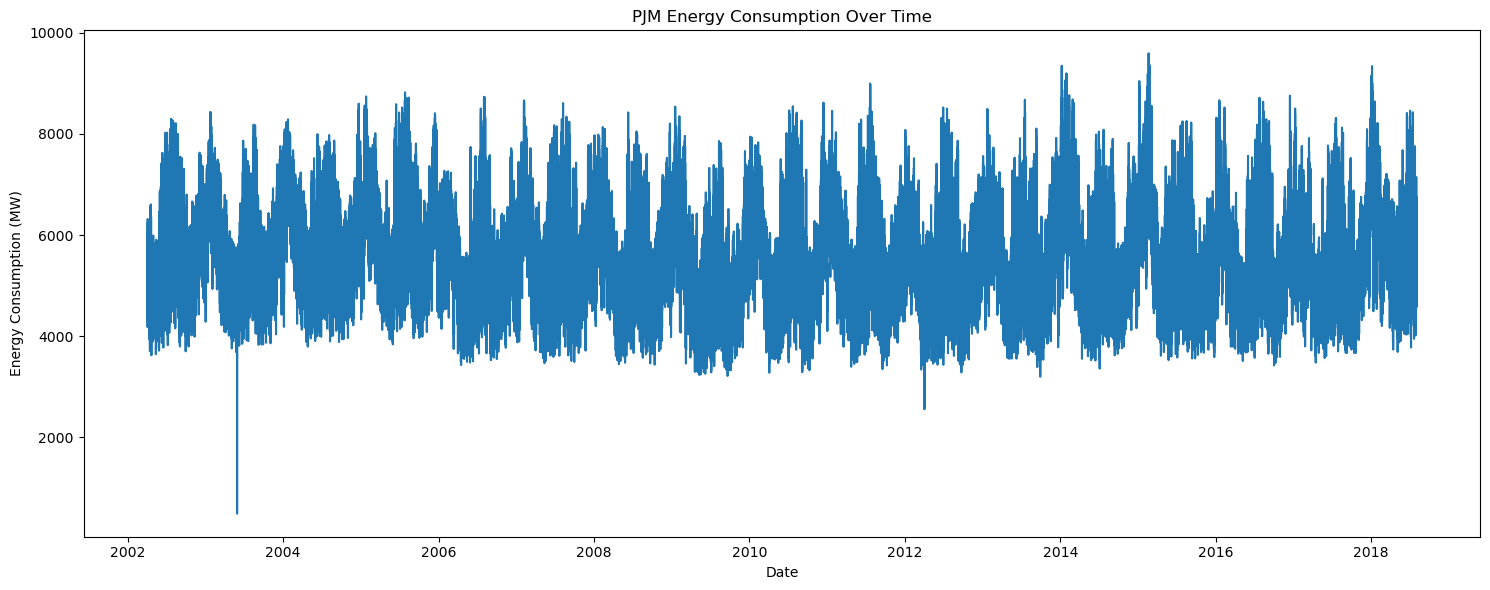

In [14]:
plt.figure(figsize=(15, 6))

plt.plot(df["Datetime"], df["PJMW_MW"])

plt.title("PJM Energy Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")

plt.tight_layout()
plt.show()

### Step 7 – Box plot (outlier check)
A box plot shows the median, the middle 50% of values, and the outliers as individual dots. It helps us spot unusual readings, in particular an extremely low value that looks like a measurement error.

In [15]:
# ============================================================
# 8.Box Plot
# ============================================================

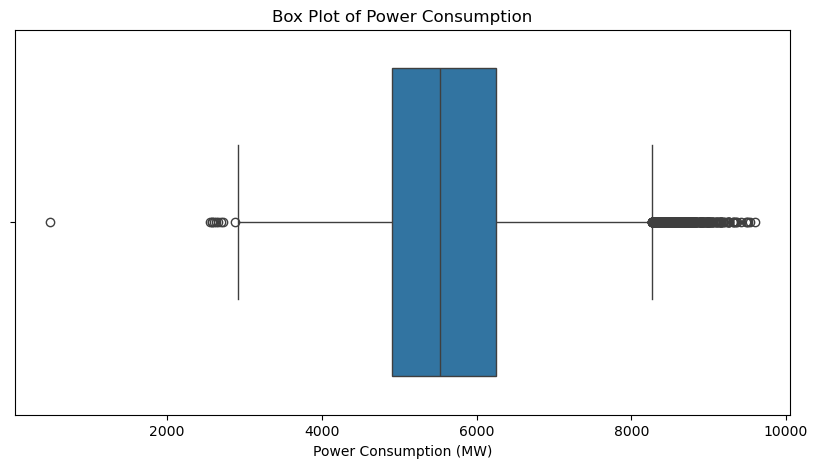

Minimum consumption: 487


In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["PJMW_MW"])

plt.title("Box Plot of Power Consumption")
plt.xlabel("Power Consumption (MW)")

plt.show()

print("Minimum consumption:", df["PJMW_MW"].min())

### Step 8 – Handle the extreme minimum value
The lowest reading is far below normal demand and is treated as an invalid value. It is replaced with `NaN` (empty) so it can be filled with a sensible value later, instead of being left in and misleading the models.
> Note: this step appears twice in the notebook (this cell and the next header). Running it twice does no harm.

In [17]:
# ============================================================
# Handle the Extreme Minimum Value
# ============================================================

In [18]:
# Replace the extreme minimum value with NaN

min_value = df["PJMW_MW"].min()

df.loc[
    df["PJMW_MW"] == min_value,
    "PJMW_MW"
] = np.nan

print("Missing values after replacing extreme minimum:")
print(df["PJMW_MW"].isnull().sum())

Missing values after replacing extreme minimum:
1


In [19]:
# ============================================================
# 8. HANDLE EXTREME MINIMUM VALUE
# ============================================================

In [20]:
# Replace the extreme minimum value with NaN
min_value = df["PJMW_MW"].min()

### Step 9 – Time-based features
Demand depends strongly on *when* it is. From the timestamp we extract `Year`, `Month`, `Day`, `Hour` and `Day_of_Week`. These become input columns the models can learn from (e.g. demand is higher in the evening than at 3 AM).

In [21]:
# ============================================================
# Time-Based Feature Engineering
# ============================================================

In [22]:
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["Day_of_Week"] = df["Datetime"].dt.day_name()

df.head()

,Datetime,PJMW_MW,Year,Month,Day,Hour,Day_of_Week
0,2002-04-01 01:00:00,4374.0,2002,4,1,1,Monday
1,2002-04-01 02:00:00,4306.0,2002,4,1,2,Monday
2,2002-04-01 03:00:00,4322.0,2002,4,1,3,Monday
3,2002-04-01 04:00:00,4359.0,2002,4,1,4,Monday
4,2002-04-01 05:00:00,4436.0,2002,4,1,5,Monday


In [23]:
# ============================================================
# Fill the Invalid Consumption Value
# ============================================================

In [24]:
# Calculate average consumption for each hour of the day

hourly_consumption = (
    df.groupby("Hour")["PJMW_MW"]
      .mean()
)

print(hourly_consumption)

# Use the average consumption at hour 0
replacement_value = hourly_consumption.loc[0]

print("\nReplacement value:", replacement_value)

# Fill the missing value
df["PJMW_MW"] = df["PJMW_MW"].fillna(replacement_value)

print("\nRemaining missing values:")
print(df["PJMW_MW"].isnull().sum())

Hour
0     5231.163426
1     4940.489276
2     4779.152349
3     4697.121996
4     4672.537366
5     4734.933479
6     4958.209450
7     5323.434316
8     5571.168398
9     5708.667058
10    5818.219169
11    5904.120476
12    5947.523794
13    5959.946716
14    5970.935824
15    5953.164712
16    5957.636394
17    6031.231233
18    6158.806803
19    6199.285355
20    6183.568365
21    6152.210121
22    5982.300436
23    5618.226206
Name: PJMW_MW, dtype: float64

Replacement value: 5231.163426081126

Remaining missing values:
0


Explanation:
The invalid value is replaced using an hourly consumption value rather than an arbitrary constant.

Small improvement: For a production-quality project, we could use interpolation or a more local imputation method, but your current approach is acceptable for this project.

### Step 10 – Verify the cleaning
Draws the box plot again after the fix. The extreme low outlier should be gone, which confirms the cleaning worked.

In [25]:
# ============================================================
# Verify Cleaning
# ============================================================

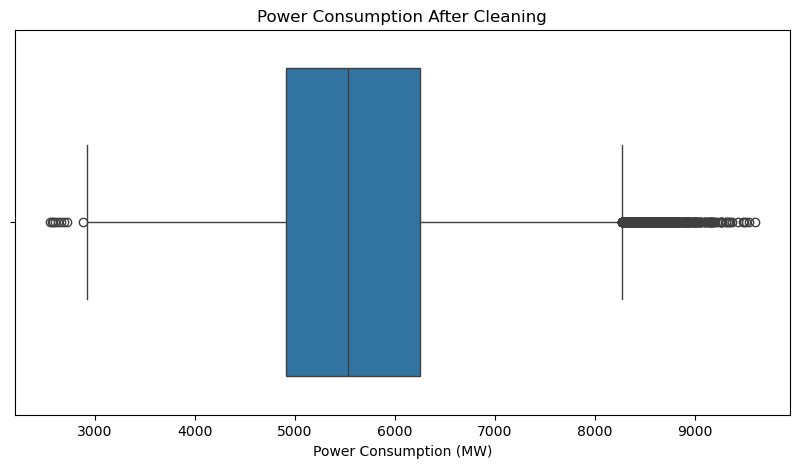

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["PJMW_MW"])

plt.title("Power Consumption After Cleaning")
plt.xlabel("Power Consumption (MW)")

plt.show()


### Cleaned time series
The same line plot as before, now on the cleaned data. The sudden unrealistic drop should no longer appear.

In [27]:
# ============================================================
# Cleaned Time-Series Plot
# ============================================================

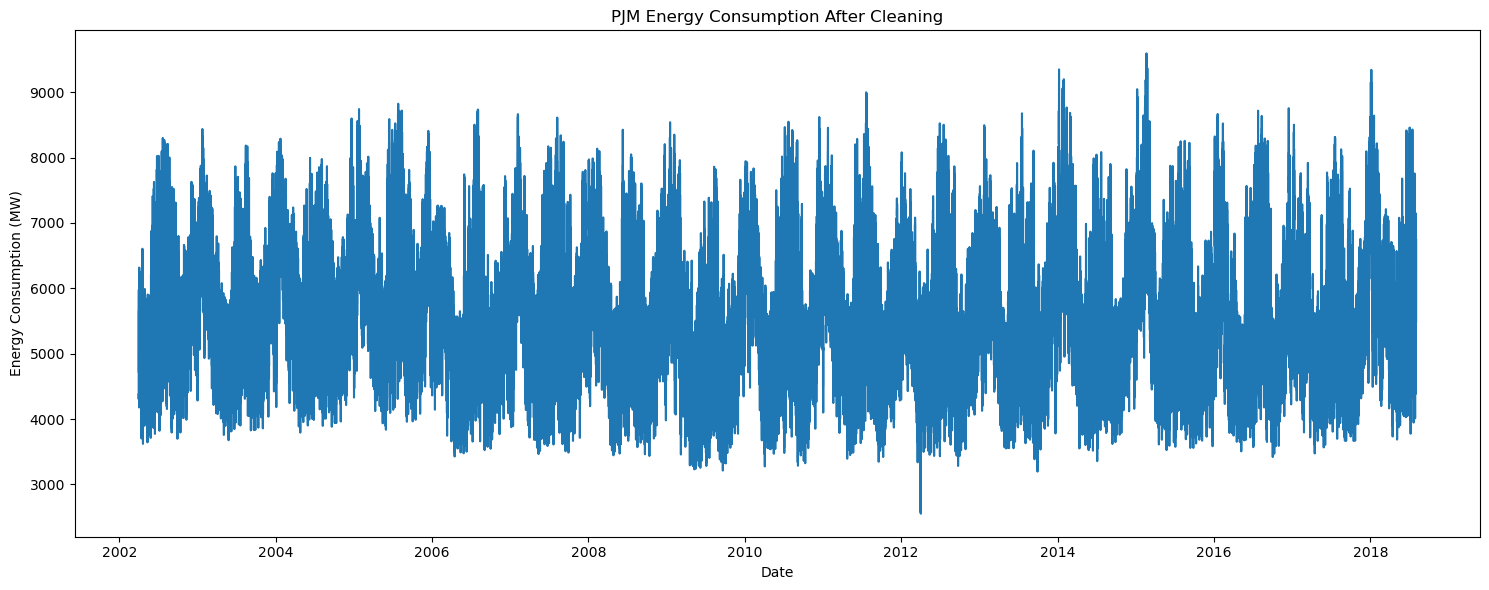

In [28]:
plt.figure(figsize=(15, 6))

plt.plot(df["Datetime"], df["PJMW_MW"])

plt.title("PJM Energy Consumption After Cleaning")
plt.xlabel("Date")
plt.ylabel("Energy Consumption (MW)")

plt.tight_layout()
plt.show()

### Pattern 1 – Average demand by hour of the day
Shows the **daily cycle**: demand is lowest at night, rises in the morning, and peaks in the evening. This is why `Hour` is an important feature.

In [29]:
# ============================================================
# Average Consumption by Hour
# ============================================================

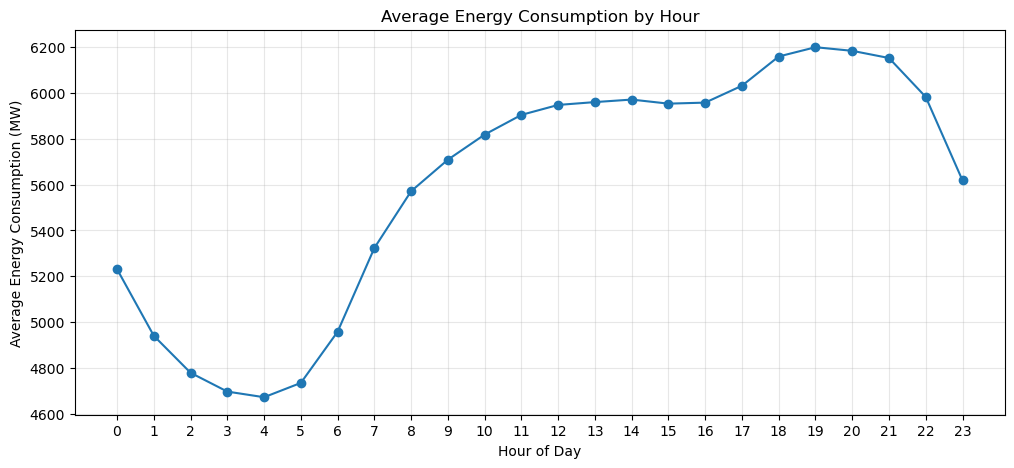

In [30]:
hourly_consumption = (
    df.groupby("Hour")["PJMW_MW"]
      .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_consumption.index,
    hourly_consumption.values,
    marker="o"
)

plt.title("Average Energy Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Consumption (MW)")

plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

### Pattern 2 – Average demand by month
Shows the **yearly cycle**. Demand is usually higher in the cold winter months (heating) and hot summer months (cooling) than in spring and autumn. This is why `Month` is a useful feature.

In [31]:
# ============================================================
# Average Consumption by Month
# ============================================================

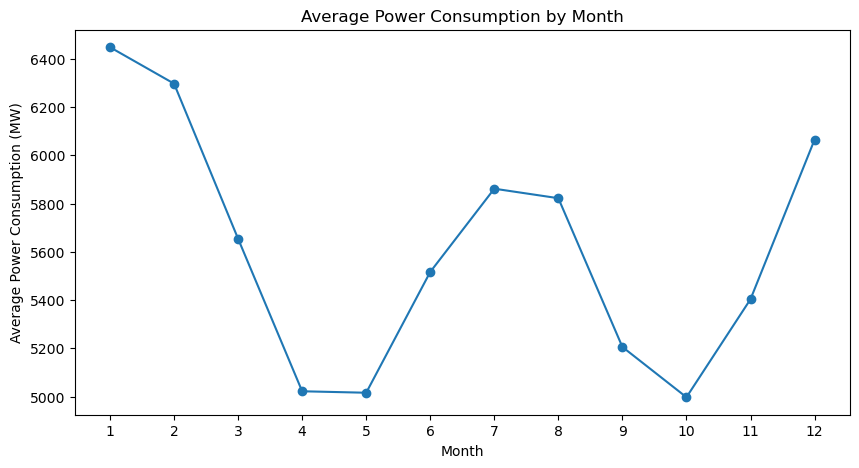

In [32]:
monthly_data = (
    df.groupby("Month")["PJMW_MW"]
      .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_data.index,
    monthly_data.values,
    marker="o"
)

plt.title("Average Power Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Power Consumption (MW)")

plt.xticks(range(1, 13))

plt.show()

### Pattern 3 – Average demand by day of the week
Compares Monday to Sunday. Weekdays normally use more electricity (offices, industry) than weekends, so day of the week is also a useful feature.

In [33]:
# ============================================================
# Average Consumption by Day
# ============================================================

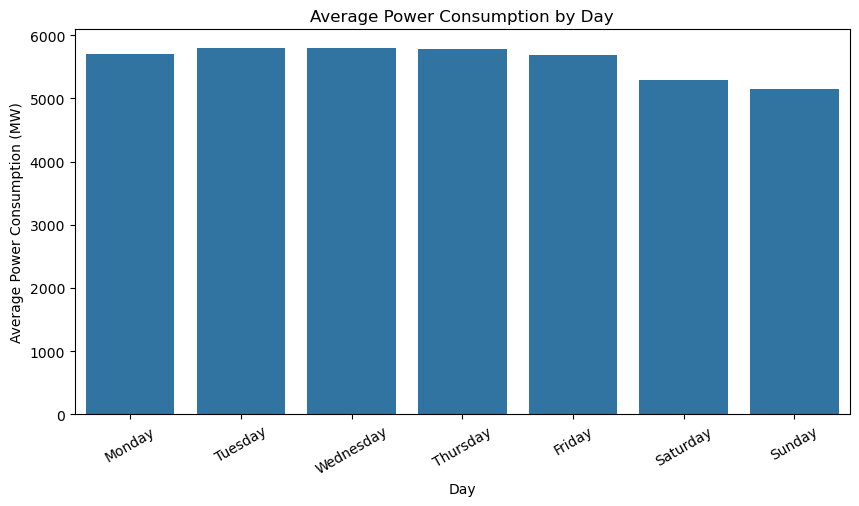

In [34]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_data = (
    df.groupby("Day_of_Week")["PJMW_MW"]
      .mean()
      .reindex(day_order)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekly_data.index,
    y=weekly_data.values
)

plt.title("Average Power Consumption by Day")
plt.xlabel("Day")
plt.ylabel("Average Power Consumption (MW)")

plt.xticks(rotation=30)

plt.show()

### Season feature
Groups months into seasons (Winter: Dec–Feb, Summer: Jun–Aug, Other: the remaining months). It gives the model a simple way to separate high-demand seasons from the rest.

In [35]:
# ============================================================
# Create Season Feature
# ============================================================

In [36]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Other"


df["Season"] = df["Month"].apply(get_season)

df[["Month", "Season"]].head()

,Month,Season
0,4,Other
1,4,Other
2,4,Other
3,4,Other
4,4,Other


### Seasonal analysis – Summer vs Winter
Compares the daily demand pattern of summer and winter. It shows that the *shape* and *level* of demand differ by season, which supports using season as a feature.

In [37]:
# ============================================================
# Seasonal Analysis
# ============================================================

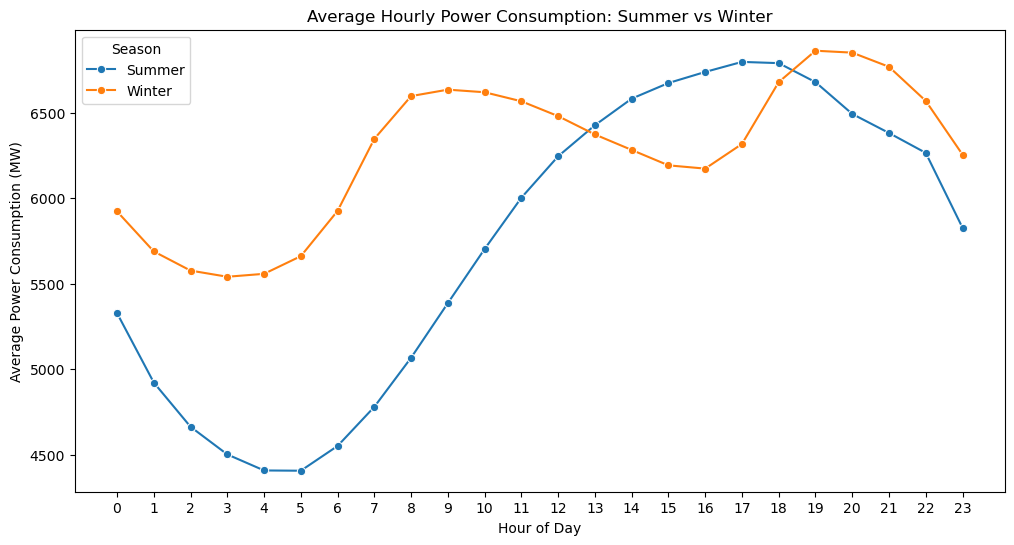

In [38]:
df_seasons = df[
    df["Season"].isin(["Summer", "Winter"])
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_seasons,
    x="Hour",
    y="PJMW_MW",
    hue="Season",
    errorbar=None,
    marker="o"
)

plt.title("Average Hourly Power Consumption: Summer vs Winter")
plt.xlabel("Hour of Day")
plt.ylabel("Average Power Consumption (MW)")
plt.xticks(range(24))

plt.show()

### Seasonal distribution
A box plot of demand for summer vs winter, showing the spread and typical level in each season.

In [39]:
# ============================================================
# Seasonal Distribution
# ============================================================

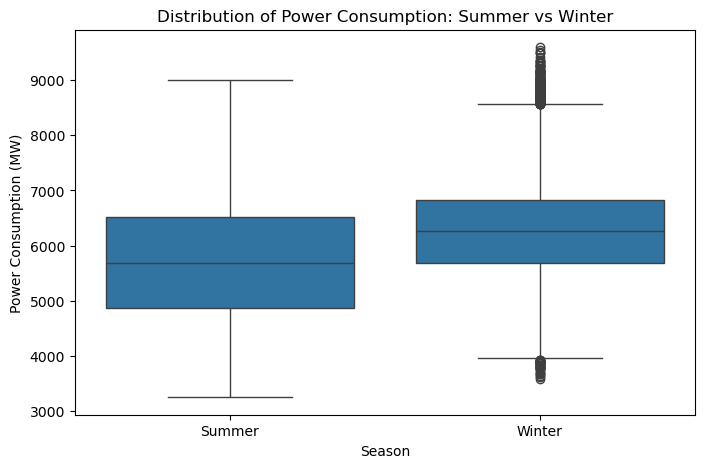

          count         mean          std     min     25%     50%     75%  \
Season                                                                      
Summer  36841.0  5734.206129  1077.573497  3255.0  4872.0  5688.0  6526.0   
Winter  34655.0  6268.813851   848.264651  3585.0  5681.0  6258.0  6834.0   

           max  
Season          
Summer  8998.0  
Winter  9594.0  


In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_seasons,
    x="Season",
    y="PJMW_MW"
)

plt.title("Distribution of Power Consumption: Summer vs Winter")
plt.ylabel("Power Consumption (MW)")

plt.show()

print(
    df_seasons.groupby("Season")["PJMW_MW"]
    .describe()
)

### Daily, weekly and monthly resampling (next three plots)
Hourly data is very dense and noisy. **Resampling** averages it into daily, weekly and monthly values so that the long-term trend and seasonal waves are easier to see. This is for understanding only; the models still use the hourly data.

In [41]:
# ============================================================
# Daily Resampling
# ============================================================

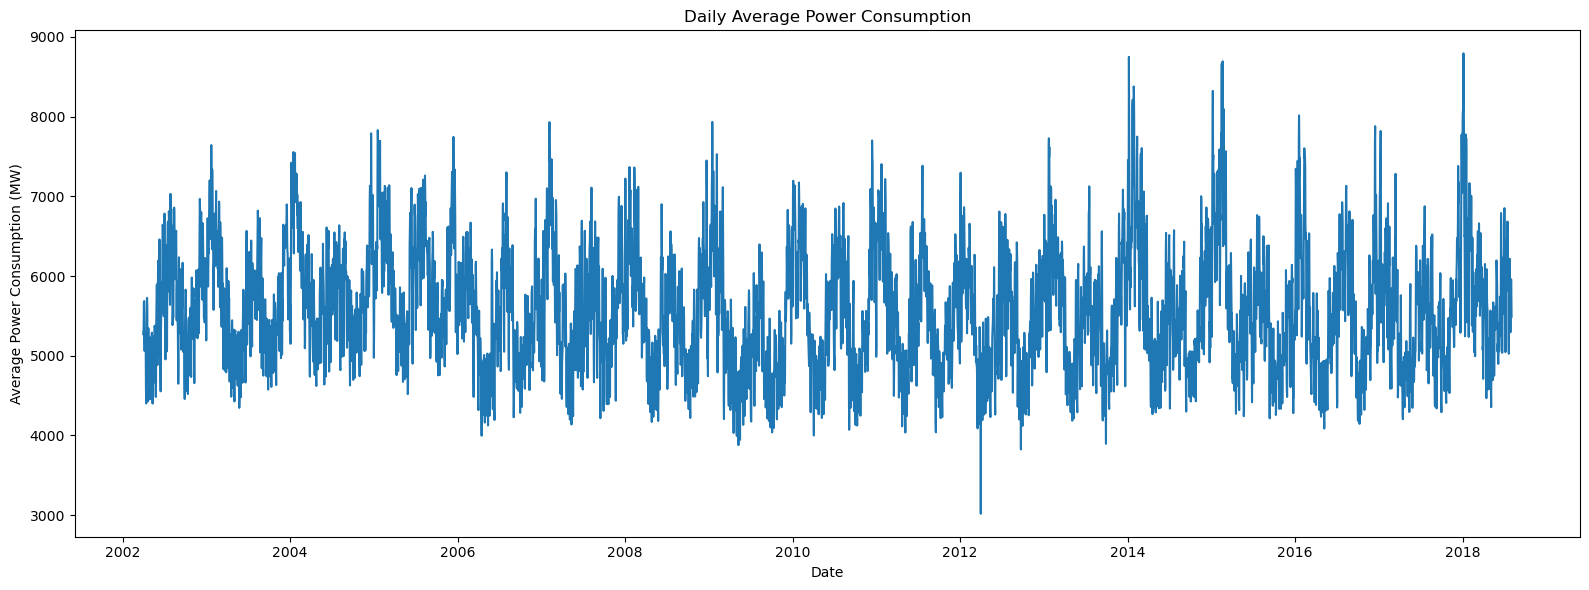

In [42]:
daily_data = (
    df.set_index("Datetime")["PJMW_MW"]
      .resample("D")
      .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(daily_data)

plt.title("Daily Average Power Consumption")
plt.xlabel("Date")
plt.ylabel("Average Power Consumption (MW)")

plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# weekly Resampling
# ============================================================

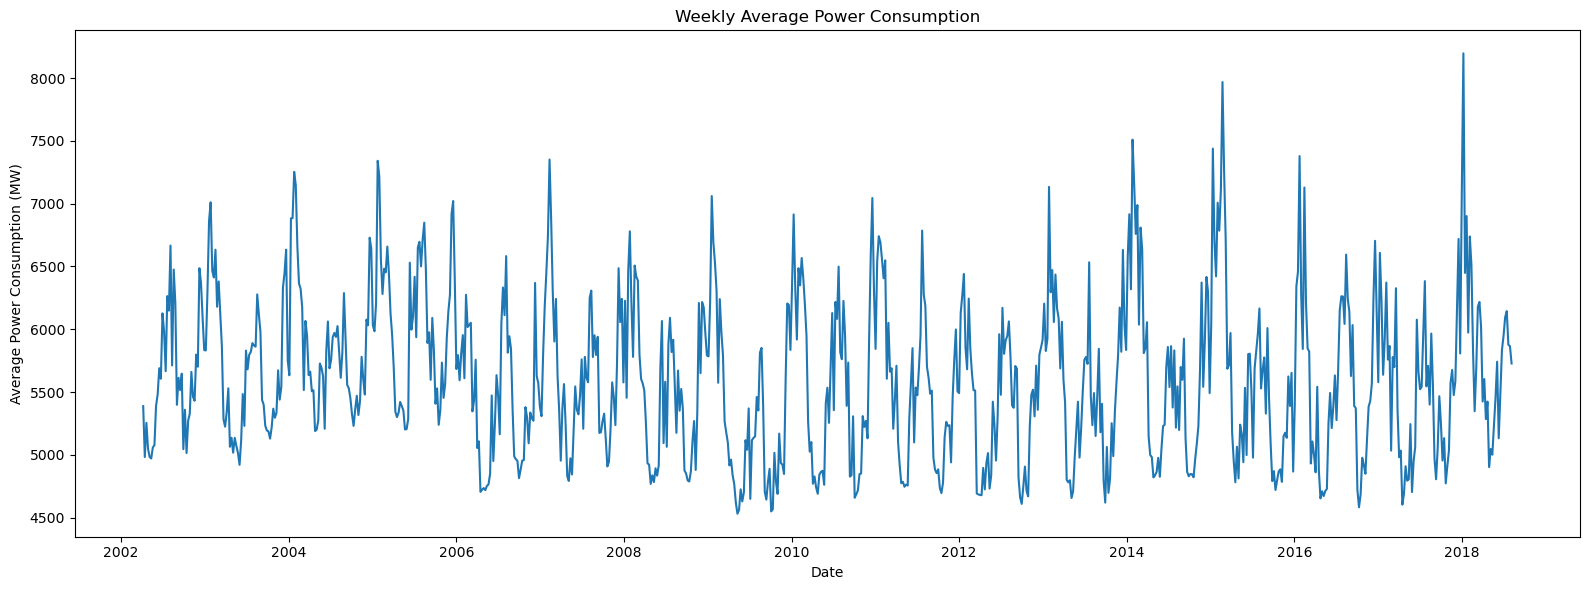

In [44]:
weekly_resampled = (
    df.set_index("Datetime")["PJMW_MW"]
      .resample("W")
      .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(weekly_resampled)

plt.title("Weekly Average Power Consumption")
plt.xlabel("Date")
plt.ylabel("Average Power Consumption (MW)")

plt.tight_layout()
plt.show()

In [45]:
# ============================================================
# Monthly Resampling
# ============================================================

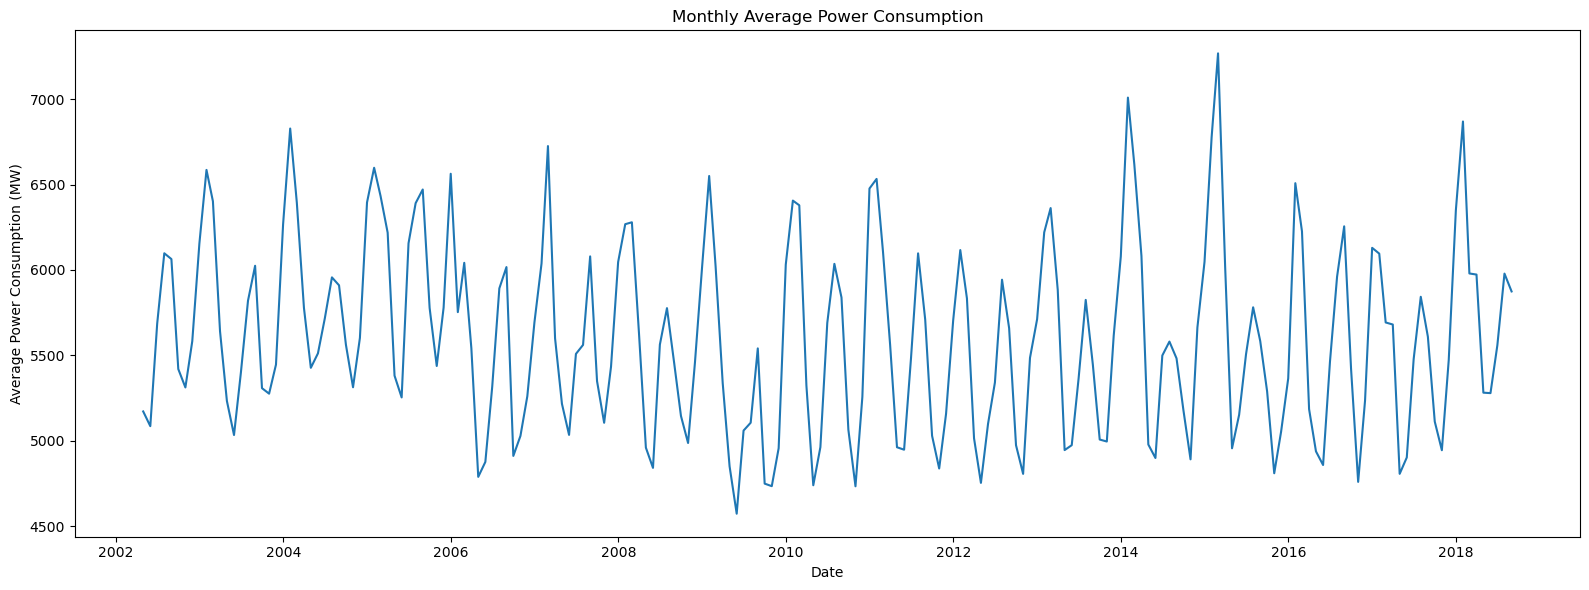

In [46]:
monthly_resampled = (
    df.set_index("Datetime")["PJMW_MW"]
      .resample("ME")
      .mean()
)

plt.figure(figsize=(16, 6))

plt.plot(monthly_resampled)

plt.title("Monthly Average Power Consumption")
plt.xlabel("Date")
plt.ylabel("Average Power Consumption (MW)")

plt.tight_layout()
plt.show()

### Step 11 – Lag features (the most important step)
A **lag feature** is the demand from an earlier time:
- `lag_1` – 1 hour ago
- `lag_24` – same hour yesterday
- `lag_168` – same hour one week ago (24 × 7)
- `lag_720` – same hour about 30 days ago (24 × 30)

Electricity demand is strongly linked to its own recent past, so these give the models the information they need to make good predictions.

In [47]:
# ============================================================
# Create Lag Features
# ============================================================

In [48]:
df["lag_1"] = df["PJMW_MW"].shift(1)
df["lag_24"] = df["PJMW_MW"].shift(24)
df["lag_168"] = df["PJMW_MW"].shift(168)
df["lag_720"] = df["PJMW_MW"].shift(720)

df[
    [
        "PJMW_MW",
        "lag_1",
        "lag_24",
        "lag_168",
        "lag_720"
    ]
].head(10)

,PJMW_MW,lag_1,lag_24,lag_168,lag_720
0,4374.0,NaN,NaN,NaN,NaN
1,4306.0,4374.0,NaN,NaN,NaN
2,4322.0,4306.0,NaN,NaN,NaN
3,4359.0,4322.0,NaN,NaN,NaN
4,4436.0,4359.0,NaN,NaN,NaN
5,4723.0,4436.0,NaN,NaN,NaN
6,5180.0,4723.0,NaN,NaN,NaN
7,5482.0,5180.0,NaN,NaN,NaN
8,5616.0,5482.0,NaN,NaN,NaN
9,5722.0,5616.0,NaN,NaN,NaN


### Correlation analysis
Shows how strongly each column is related to `PJMW_MW` (values close to +1 or −1 mean a strong relationship). The lag features typically show very high correlation, which confirms they are worth using.

In [49]:
# ============================================================
# Correlation Analysis
# ============================================================

In [50]:
correlation = (
    df.corr(numeric_only=True)["PJMW_MW"]
      .sort_values()
)

print(correlation)

Month     -0.152441
Year      -0.046988
Day       -0.006121
Hour       0.447225
lag_720    0.507029
lag_168    0.759379
lag_24     0.877276
lag_1      0.974818
PJMW_MW    1.000000
Name: PJMW_MW, dtype: float64


In [51]:
# ============================================================
# Remove Rows With Missing Lag Values
# ============================================================

In [52]:
df = df.dropna(
    subset=[
        "lag_1",
        "lag_24",
        "lag_168",
        "lag_720"
    ]
).reset_index(drop=True)

print("Dataset shape after lag creation:")
print(df.shape)

print("\nMissing values in lag features:")
print(
    df[
        [
            "lag_1",
            "lag_24",
            "lag_168",
            "lag_720"
        ]
    ].isnull().sum()
)

Dataset shape after lag creation:
(142486, 12)

Missing values in lag features:
lag_1      0
lag_24     0
lag_168    0
lag_720    0
dtype: int64


Explanation:
The first 720 rows don't have enough historical information to calculate lag_720, so they are removed rather than artificially filled.

In [53]:
# ============================================================
# One-Hot Encoding
# ============================================================

In [54]:
df = pd.get_dummies(
    df,
    columns=["Day_of_Week", "Season"],
    dtype=int
)

df.head()

,Datetime,PJMW_MW,Year,Month,Day,Hour,lag_1,lag_24,lag_168,lag_720,Day_of_Week_Friday,Day_of_Week_Monday,Day_of_Week_Saturday,Day_of_Week_Sunday,Day_of_Week_Thursday,Day_of_Week_Tuesday,Day_of_Week_Wednesday,Season_Other,Season_Summer,Season_Winter
0,2002-05-01 02:00:00,4418.0,2002,5,1,2,4503.0,4599.0,4738.0,4374.0,0,0,0,0,0,0,1,1,0,0
1,2002-05-01 03:00:00,4310.0,2002,5,1,3,4418.0,4528.0,4711.0,4306.0,0,0,0,0,0,0,1,1,0,0
2,2002-05-01 04:00:00,4282.0,2002,5,1,4,4310.0,4555.0,4743.0,4322.0,0,0,0,0,0,0,1,1,0,0
3,2002-05-01 05:00:00,4431.0,2002,5,1,5,4282.0,4654.0,4912.0,4359.0,0,0,0,0,0,0,1,1,0,0
4,2002-05-01 06:00:00,4732.0,2002,5,1,6,4431.0,4940.0,5255.0,4436.0,0,0,0,0,0,0,1,1,0,0


Explanation:
Machine-learning models require categorical variables such as day names and seasons to be converted into numerical columns.

### Step 12 – Define features (X) and target (y)
- **X (inputs):** lag features, hour, month, year, day-of-week columns and season columns
- **y (target):** `PJMW_MW`, the value we want to predict

In [55]:
# ============================================================
# Define Features and Target
# ============================================================

In [56]:
features = [
    "lag_1",
    "lag_24",
    "lag_168",
    "lag_720",
    "Hour",
    "Month",
    "Year",
    "Day_of_Week_Monday",
    "Day_of_Week_Tuesday",
    "Day_of_Week_Wednesday",
    "Day_of_Week_Thursday",
    "Day_of_Week_Friday",
    "Day_of_Week_Saturday",
    "Day_of_Week_Sunday",
    "Season_Summer",
    "Season_Winter",
    "Season_Other"
]

X = df[features]
y = df["PJMW_MW"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (142486, 17)
y shape: (142486,)


In [57]:
# ============================================================
# Train-Test Split
# ============================================================

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=False
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining period:")
print(df["Datetime"].iloc[:len(X_train)].min())
print(df["Datetime"].iloc[:len(X_train)].max())

print("\nTesting period:")
print(df["Datetime"].iloc[len(X_train):].min())
print(df["Datetime"].iloc[len(X_train):].max())

Training samples: 113988
Testing samples : 28498

Training period:
2002-05-01 02:00:00
2015-05-03 14:00:00

Testing period:
2015-05-03 15:00:00
2018-08-03 00:00:00


Explanation:
shuffle=False is essential for time-series forecasting. The model trains on the past and is evaluated on the future.

## Model training

We train several models on the same training data and judge them on the same test data. Three metrics are used (all measured on the test set):

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | Average size of the error in MW | Lower |
| **RMSE** | Like MAE but penalises big mistakes more | Lower |
| **R²** | How much of the variation in demand the model explains (1.0 = perfect) | Higher |

### Model 1 – Linear Regression
The simplest model. It fits a straight-line relationship between the inputs and demand. It is our **baseline**: other models should beat it to be worth using.

In [59]:
# ============================================================
# Linear Regression
# ============================================================

In [60]:
model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("---------------------------")
print(f"MAE  : {mae_lr:.4f}")
print(f"RMSE : {rmse_lr:.4f}")
print(f"R²   : {r2_lr:.4f}")

Linear Regression
---------------------------
MAE  : 155.1054
RMSE : 196.1857
R²   : 0.9611


### Model 2 – Random Forest
Builds 200 decision trees and averages their predictions. It can capture non-linear patterns (like the daily and seasonal cycles) that Linear Regression misses, and it is more robust against over-fitting.

In [61]:
# ============================================================
# Random Forest
# ============================================================

In [62]:
model_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("---------------------------")
print(f"MAE  : {mae_rf:.4f}")
print(f"RMSE : {rmse_rf:.4f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest
---------------------------
MAE  : 60.5617
RMSE : 79.7117
R²   : 0.9936


### Model 3 – XGBoost
A powerful *gradient boosting* model. It builds trees one after another, each one correcting the errors of the previous ones. It is often among the most accurate models for tabular data like this.

In [63]:
# ============================================================
# XGBoost
# ============================================================

In [64]:
model_xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost")
print("---------------------------")
print(f"MAE  : {mae_xgb:.4f}")
print(f"RMSE : {rmse_xgb:.4f}")
print(f"R²   : {r2_xgb:.4f}")

XGBoost
---------------------------
MAE  : 61.5726
RMSE : 81.7871
R²   : 0.9932


### Save the XGBoost model
Saves the trained model (`pjm_xgboost_model.pkl`) and the list of feature names (`xgb_features.pkl`). Later they can be loaded to make predictions without training again. The feature list ensures new data has the same columns in the same order.

In [65]:
import joblib

joblib.dump(model_xgb, "pjm_xgboost_model.pkl")

['pjm_xgboost_model.pkl']

In [66]:
joblib.dump(features, "xgb_features.pkl")

['xgb_features.pkl']

### Model 4 – ANN (Artificial Neural Network)
A neural network with several fully-connected layers. Unlike the tree models, neural networks need **scaled inputs**, so the next cell first standardises the features and the target.
- **Dropout** randomly switches off some neurons during training to reduce over-fitting.
- **EarlyStopping** stops training when validation loss stops improving and keeps the best weights.
- Predictions are converted back to MW before computing MAE, RMSE and R².

In [67]:
# ============================================================
# ANN
# ============================================================

In [68]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Scale features and target (fit on training data only)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_ann = scaler_X.fit_transform(X_train)
X_test_ann = scaler_X.transform(X_test)
y_train_ann = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()

# Build ANN
model_ann = Sequential([
    Input(shape=(X_train_ann.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model_ann.compile(optimizer="adam", loss="mse", metrics=["mae"])

early_stop_ann = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train
history_ann = model_ann.fit(
    X_train_ann,
    y_train_ann,
    epochs=50,
    batch_size=256,
    validation_split=0.1,
    callbacks=[early_stop_ann],
    verbose=1
)

# Predict and convert back to MW
y_pred_ann = scaler_y.inverse_transform(
    model_ann.predict(X_test_ann, verbose=0)
).ravel()

mae_ann = mean_absolute_error(y_test, y_pred_ann)
rmse_ann = np.sqrt(mean_squared_error(y_test, y_pred_ann))
r2_ann = r2_score(y_test, y_pred_ann)

print("ANN")
print("---------------------------")
print(f"MAE  : {mae_ann:.4f}")
print(f"RMSE : {rmse_ann:.4f}")
print(f"R²   : {r2_ann:.4f}")

Epoch 1/50
401/401 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - loss: 0.0976 - mae: 0.2310 - val_loss: 0.0534 - val_mae: 0.1839
Epoch 2/50
401/401 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0425 - mae: 0.1606 - val_loss: 0.0690 - val_mae: 0.2094
Epoch 3/50
401/401 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0344 - mae: 0.1440 - val_loss: 0.0897 - val_mae: 0.2330
Epoch 4/50
401/401 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0299 - mae: 0.1334 - val_loss: 0.0993 - val_mae: 0.2422
Epoch 5/50
401/401 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0272 - mae: 0.1270 - val_loss: 0.0913 - val_mae: 0.2343
Epoch 6/50
401/401 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0255 - mae: 0.1228 - val_loss: 0.0820 - val_mae: 0.2215
ANN
---------------------------
MAE  : 178.7770
RMSE : 217.7060
R²   : 0.9521


#### Data preparation for the LSTM
The next cell builds the sequences used by the **LSTM** model later (it sits here in the notebook, but is used in the LSTM section). Each sample is the **previous 24 hours** and the target is the **next hour**. The scaler is fitted on training data only, so no information from the test period leaks into training.

In [69]:


data = df["PJMW_MW"].values.reshape(-1, 1)

split_raw = int(len(data) * 0.8)

train_data = data[:split_raw]
test_data = data[split_raw:]

scaler_lstm = MinMaxScaler()

train_scaled = scaler_lstm.fit_transform(train_data)
test_scaled = scaler_lstm.transform(test_data)

sequence_length = 24

X_train_lstm = []
y_train_lstm = []

for i in range(sequence_length, len(train_scaled)):
    X_train_lstm.append(train_scaled[i-sequence_length:i])
    y_train_lstm.append(train_scaled[i])

X_test_lstm = []
y_test_lstm = []

for i in range(sequence_length, len(test_scaled)):
    X_test_lstm.append(test_scaled[i-sequence_length:i])
    y_test_lstm.append(test_scaled[i])

X_train_lstm = np.array(X_train_lstm)
y_train_lstm = np.array(y_train_lstm)

X_test_lstm = np.array(X_test_lstm)
y_test_lstm = np.array(y_test_lstm)

print("X_train:", X_train_lstm.shape)
print("X_test:", X_test_lstm.shape)

X_train: (113964, 24, 1)
X_test: (28474, 24, 1)


### ANN loss curve
Plots training loss and validation loss for each epoch. If both fall and stay close together, the network is learning well. A growing gap (validation much higher than training) means over-fitting.

In [70]:
# ============================================================
# ANN Loss Curve
# ============================================================

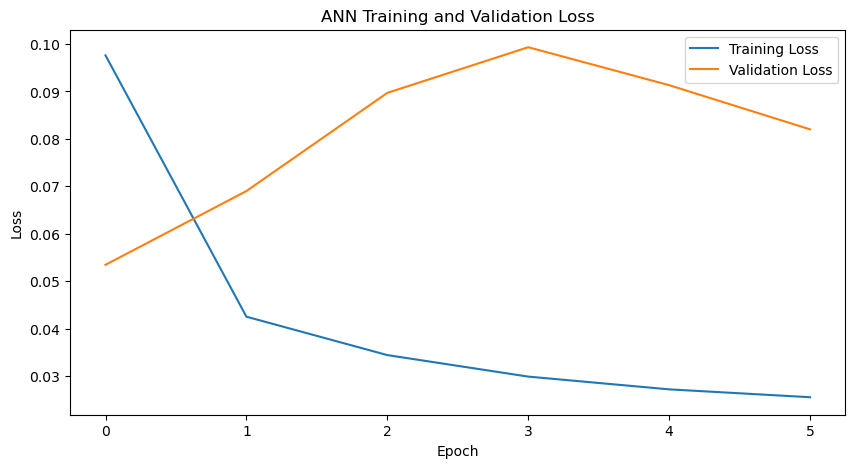

In [71]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_ann.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_ann.history["val_loss"],
    label="Validation Loss"
)

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

### Model 5 – LSTM (Long Short-Term Memory)
A deep-learning model designed for **sequences**. Instead of manually created lag columns, it reads the last 24 hours as a sequence and learns the time patterns itself. It is well suited to hourly demand data.

In [72]:
# ============================================================
# LSTM
# ============================================================

In [73]:
# ---------------------------------------------------------
# Prepare target
# ---------------------------------------------------------

data = df["PJMW_MW"].values.reshape(-1, 1)

# ---------------------------------------------------------
# Train-test split first
# ---------------------------------------------------------

split_raw = int(len(data) * 0.8)

train_data = data[:split_raw]
test_data = data[split_raw:]

# ---------------------------------------------------------
# Scale using training data only
# ---------------------------------------------------------

scaler_lstm = MinMaxScaler()

train_scaled = scaler_lstm.fit_transform(train_data)
test_scaled = scaler_lstm.transform(test_data)

# ---------------------------------------------------------
# Create sequences
# ---------------------------------------------------------

sequence_length = 24

X_train_lstm = []
y_train_lstm = []

for i in range(sequence_length, len(train_scaled)):
    X_train_lstm.append(
        train_scaled[i-sequence_length:i]
    )
    y_train_lstm.append(
        train_scaled[i]
    )

X_test_lstm = []
y_test_lstm = []

for i in range(sequence_length, len(test_scaled)):
    X_test_lstm.append(
        test_scaled[i-sequence_length:i]
    )
    y_test_lstm.append(
        test_scaled[i]
    )

X_train_lstm = np.array(X_train_lstm)
y_train_lstm = np.array(y_train_lstm)

X_test_lstm = np.array(X_test_lstm)
y_test_lstm = np.array(y_test_lstm)

print("X_train LSTM:", X_train_lstm.shape)
print("X_test LSTM :", X_test_lstm.shape)

X_train LSTM: (113964, 24, 1)
X_test LSTM : (28474, 24, 1)


#### Build and train the LSTM
Two stacked LSTM layers (64 and 32 units) with Dropout, followed by Dense layers that output one number: the predicted next-hour demand. EarlyStopping is used here too.

In [74]:
# ============================================================
# Build and Train LSTM
# ============================================================

In [75]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

model_lstm = Sequential([
    Input(shape=(24, 1)),

    LSTM(64, return_sequences=True),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop_lstm = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=30,
    batch_size=256,
    validation_split=0.1,
    callbacks=[early_stop_lstm],
    verbose=1
)

Epoch 1/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 41s 80ms/step - loss: 0.0135 - mae: 0.0861 - val_loss: 0.0036 - val_mae: 0.0483
Epoch 2/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 39s 75ms/step - loss: 0.0041 - mae: 0.0510 - val_loss: 0.0031 - val_mae: 0.0425
Epoch 3/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 33s 82ms/step - loss: 0.0025 - mae: 0.0393 - val_loss: 0.0016 - val_mae: 0.0306
Epoch 4/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 36s 89ms/step - loss: 0.0015 - mae: 0.0303 - val_loss: 7.9765e-04 - val_mae: 0.0225
Epoch 5/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 33s 82ms/step - loss: 0.0011 - mae: 0.0260 - val_loss: 6.3945e-04 - val_mae: 0.0196
Epoch 6/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 29s 73ms/step - loss: 9.3960e-04 - mae: 0.0238 - val_loss: 4.6477e-04 - val_mae: 0.0168
Epoch 7/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 29s 72ms/step - loss: 8.0918e-04 - mae: 0.0219 - val_loss: 3.8162e-04 - val_mae: 0.0151
Epoch 8/30
401/401 ━━━━━━━━━━━━━━━━━━━━ 30s 75ms/step - loss: 7.2256e-04 - mae: 0.0207 - val_loss: 3.7757e-04 - val_mae: 0.0157
Epoch 9/

In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_lstm_scaled = model_lstm.predict(
    X_test_lstm,
    verbose=0
)

y_pred_lstm = scaler_lstm.inverse_transform(
    y_pred_lstm_scaled
).ravel()

y_actual_lstm = scaler_lstm.inverse_transform(
    y_test_lstm
).ravel()

mae_lstm = mean_absolute_error(
    y_actual_lstm,
    y_pred_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        y_actual_lstm,
        y_pred_lstm
    )
)

r2_lstm = r2_score(
    y_actual_lstm,
    y_pred_lstm
)

print("LSTM Performance")
print("----------------")
print("MAE :", mae_lstm)
print("RMSE:", rmse_lstm)
print("R²  :", r2_lstm)

LSTM Performance
----------------
MAE : 80.50014309415224
RMSE: 104.41400261943082
R²  : 0.9889822913393047


In [78]:
import os
import pickle
from tensorflow.keras.models import load_model

# Save first (model_lstm and scaler_lstm must already be trained/created above)
model_lstm.save("pjm_lstm_model_fixed.keras")

with open("lstm_scaler.pkl", "wb") as f:
    pickle.dump(scaler_lstm, f)

# Now load it back to check it works
test_model = load_model("pjm_lstm_model_fixed.keras", compile=False)
print("Model loaded successfully!")

print(os.path.exists("pjm_lstm_model_fixed.keras"))
print(os.path.exists("lstm_scaler.pkl"))

Model loaded successfully!
True
True


In [79]:
import os

print(os.path.exists("pjm_lstm_model_fixed.keras"))
print(os.path.exists("lstm_scaler.pkl"))

True
True


#### LSTM predictions and metrics
Predicts on the test sequences, converts the scaled values back to MW, and calculates MAE, RMSE and R² so the LSTM can be compared fairly with the other models.

In [80]:
# ============================================================
# LSTM Prediction and Metrics
# ============================================================

In [81]:
y_pred_lstm_scaled = model_lstm.predict(
    X_test_lstm,
    verbose=0
)

y_pred_lstm = scaler_lstm.inverse_transform(
    y_pred_lstm_scaled
).ravel()

y_actual_lstm = scaler_lstm.inverse_transform(
    y_test_lstm
).ravel()

mae_lstm = mean_absolute_error(
    y_actual_lstm,
    y_pred_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        y_actual_lstm,
        y_pred_lstm
    )
)

r2_lstm = r2_score(
    y_actual_lstm,
    y_pred_lstm
)

print("\nLSTM")
print("---------------------------")
print(f"Epochs Completed : {len(history_lstm.history['loss'])}")
print(f"MAE              : {mae_lstm:.4f}")
print(f"RMSE             : {rmse_lstm:.4f}")
print(f"R²               : {r2_lstm:.4f}")


LSTM
---------------------------
Epochs Completed : 19
MAE              : 80.5001
RMSE             : 104.4140
R²               : 0.9890


### Model 6 – SARIMAX
A classical statistical time-series model. **S**easonal **ARI**MA with e**X**ogenous variables: it models trend, daily seasonality (24-hour cycle) and extra inputs. It is slow on large hourly data, so it is trained on a small recent portion of the data. Its score is therefore not directly comparable with the other models.

In [82]:
# ============================================================
# SARIMAX
# ============================================================

In [83]:
# ---------------------------------------------------------
# Prepare SARIMAX data
# ---------------------------------------------------------

df_sarimax = df.copy()

df_sarimax["Datetime"] = pd.to_datetime(
    df_sarimax["Datetime"]
)

df_sarimax = (
    df_sarimax
    .sort_values("Datetime")
    .set_index("Datetime")
)

# Target
y_sarimax = df_sarimax["PJMW_MW"]

# Exogenous variables
X_sarimax = df_sarimax[
    [
        "lag_1",
        "lag_24",
        "lag_168",
        "Hour",
        "Month"
    ]
]

# Remove missing values
sarimax_data = pd.concat(
    [y_sarimax, X_sarimax],
    axis=1
).dropna()

y_sarimax = sarimax_data["PJMW_MW"]
X_sarimax = sarimax_data.drop(
    columns=["PJMW_MW"]
)

# ---------------------------------------------------------
# Use the same 80/20 chronological split
# ---------------------------------------------------------

split_sarimax = int(
    len(sarimax_data) * 0.8
)

y_train_sarimax = y_sarimax.iloc[:split_sarimax]
y_test_sarimax = y_sarimax.iloc[split_sarimax:]

X_train_sarimax = X_sarimax.iloc[:split_sarimax]
X_test_sarimax = X_sarimax.iloc[split_sarimax:]

# ---------------------------------------------------------
# Use recent training data to reduce computation
# ---------------------------------------------------------

train_window = 24 * 90   # Last 90 days

y_train_sarimax_small = y_train_sarimax.iloc[-train_window:]
X_train_sarimax_small = X_train_sarimax.iloc[-train_window:]

print("SARIMAX training observations:",
      len(y_train_sarimax_small))

print("SARIMAX testing observations:",
      len(y_test_sarimax))

SARIMAX training observations: 2160
SARIMAX testing observations: 28498


In [84]:
# ============================================================
# Train SARIMAX
# ============================================================

In [85]:
model_sarimax = SARIMAX(
    y_train_sarimax_small,
    exog=X_train_sarimax_small,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit_sarimax = model_sarimax.fit(
    disp=False
)

print("SARIMAX model training completed.")

C:\Users\HI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\HI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\HI\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMAX model training completed.


In [86]:
# ============================================================
# SARIMAX Prediction and Metrics
# ============================================================

In [87]:
y_pred_sarimax = model_fit_sarimax.forecast(
    steps=len(y_test_sarimax),
    exog=X_test_sarimax
)

mae_sarimax = mean_absolute_error(
    y_test_sarimax,
    y_pred_sarimax
)

rmse_sarimax = np.sqrt(
    mean_squared_error(
        y_test_sarimax,
        y_pred_sarimax
    )
)

r2_sarimax = r2_score(
    y_test_sarimax,
    y_pred_sarimax
)

print("\nSARIMAX")
print("---------------------------")
print(f"MAE  : {mae_sarimax:.4f}")
print(f"RMSE : {rmse_sarimax:.4f}")
print(f"R²   : {r2_sarimax:.4f}")

C:\Users\HI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\HI\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(



SARIMAX
---------------------------
MAE  : 6945.7323
RMSE : 7956.7154
R²   : -62.9745


## Model comparison
All models' metrics are collected in one table. **The best model has the lowest MAE and RMSE and the highest R².** The next cell shows the same comparison as a bar chart.

In [88]:
# ============================================================
# Model Comparison Table
# ============================================================

In [89]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "XGBoost",
        "Random Forest",
        "ANN",
        "LSTM",

    ],
    
    "MAE": [
        mae_lr,
        mae_rf,
        mae_xgb,
        mae_ann,
        mae_lstm
    ],
    
    "RMSE": [
        rmse_lr,
        rmse_rf,
        rmse_xgb,
        rmse_ann,
        rmse_lstm
    ],
    
    "R²": [
        r2_lr,
        r2_rf,
        r2_xgb,
        r2_ann,
        r2_lstm
    ]
})

comparison = comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

comparison

,Model,MAE,RMSE,R²
0,XGBoost,60.561656,79.711674,0.993579
1,Random Forest,61.572609,81.787135,0.993241
2,LSTM,80.500143,104.414003,0.988982
3,Linear Regression,155.105448,196.185687,0.961107
4,ANN,178.777049,217.705984,0.952106


In [90]:
# ============================================================
# Visual Comparison of Models
# ============================================================

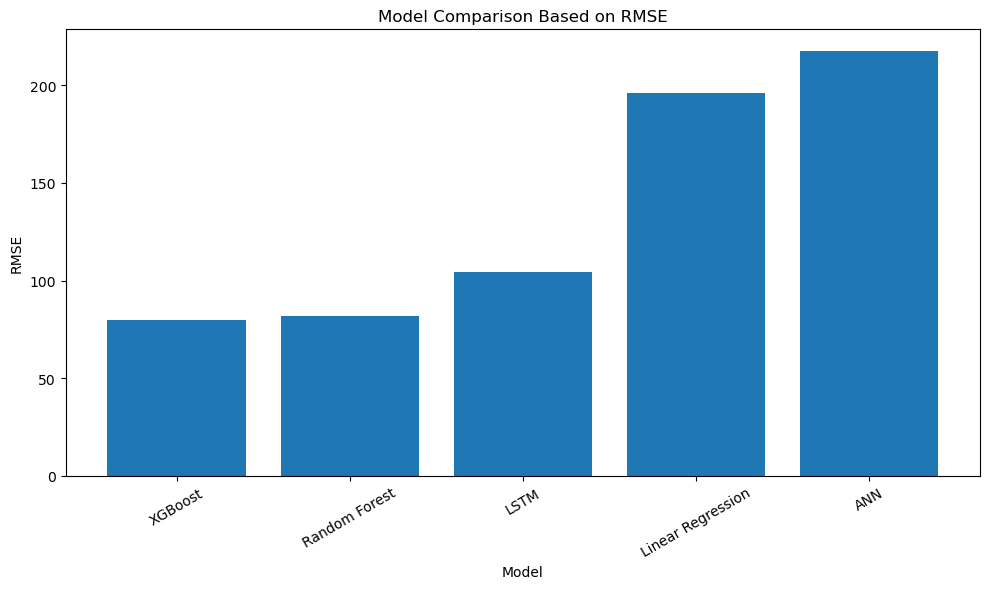

In [91]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["RMSE"]
)

plt.title("Model Comparison Based on RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

### Save the LSTM model and scaler
Saves the trained LSTM (`pjm_lstm_model.keras`) and its scaler (`lstm_scaler.pkl`). The scaler must be saved too, because new data has to be scaled in exactly the same way before it is fed to the LSTM.

In [92]:
import pickle

# Save LSTM model
model_lstm.save("pjm_lstm_model.keras")

# Save the scaler
with open("lstm_scaler.pkl", "wb") as file:
    pickle.dump(scaler_lstm, file)

print("LSTM model and scaler saved successfully.")

LSTM model and scaler saved successfully.


In [1]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.15.0
